# Загружаем данные

Рассмотрим данные из соревнования по предсказанию стоимости жилья

In [80]:
import pandas as pd

In [78]:
!wget  -O 'train.csv' -q 'https://www.dropbox.com/s/6dxq90t0prn2vaw/_train_sem2.csv?dl=0'

In [81]:
data = pd.read_csv("train.csv")
data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Первое, что стоит заметить &mdash; у нас в данных есть уникальное для каждого объекта поле id. Обычно такие поля только мешают и способствуют переобучению. Удалим это поле из данных.

Разделим данные на обучающую и тестовую выборки. Для простоты не будем выделять дополнительно валидационную выборку (хотя это обычно стоит делать, она нужна для подбора гиперпараметров модели, то есть параметров, которые нельзя подбирать по обучающей выборке). Дополнительно нам придется отделить значения целевой переменной от данных.

**Вопрос 1**: Почему поля типа id могут вызвать переобучение модели (не обязательно линейной)?

**Вопрос 2**: Почему стоит дополнительно отделять валидационную выборку?

**Вопрос 3**: Обратите внимание на фиксацию `random_state` при сплите данных. Почему это важно?

In [82]:
# np.random.seed(36)
from sklearn.model_selection import train_test_split

data = data.drop(columns=["Id"])

y = data["SalePrice"] # целевая переменная (target)
X = data.drop(columns=["SalePrice"]) # из пространства признаков выкинули целевую переменную

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

# Задание
- 1) Проведите EDA анализ данных
- 2) Выберите наиболее релевантные факторы для прогноза
- 3) Подберите лучшую модель (используйте в качестве метрики качества показатель RMSE)
- 4) Проверьте качество данной модели - на сколько она точна, насколько стабильна, насколько правильно специфирована

**Вопросы:**

**Вопрос 1**: Почему поля типа id могут вызвать переобучение модели (не обязательно линейной)?
Поля типа id могут вызывать переобучение модели по нескольким причинам:
1) id сохраняет порядок. В случае классификации таргеты могут быть кластеризированы в таблице(1-1000 - класс №1, 1001-2000 - класс №2 и тд.). За счёт этого модель может сделать ложный вывод о связи id и таргета. Вызовет проблемы на тестовой выборке.
2) Модель может запомнить id конкретных строк и их таргеты.
3) Если выгрузка делалась в зависимости от даты/времени, то возникает корреляция с id. При разделении данных по дате/времени происходит расхождение для тестовой и обучающей выборках(для test id могут быть всегда меньше, чем для train), что приведёт к странным ответам модели.
4) Модель может найти несуществующую связь id с таргетом при обучении. На новых данных такая связь будет отсутствовать(могут быть загруженные данные с id, которые встречались на обучающей выборки, но сами данные будут различаться)

**Вопрос 2**: Почему стоит дополнительно отделять валидационную выборку?
Валидационная выборка используется для подбора гипер-параметров, выбора границы для ранней остановки обучения, проверки работы модели(переобучение/недообучение). Если не использовать валидационную выборку, а настраивать модель на тестовой выборке это может привести к утечке данных. Модель может подстроиться под тестовые данные и дать результат лучше, чем есть на самом деле.


**Вопрос 3**: Обратите внимание на фиксацию `random_state` при сплите данных. Почему это важно?
random_state при сплите данных необходим, чтоб разбиение выборок было идентичным при нескольких запусков разделения данных. Это не обходимо при настройке гипер параметров(при разных выборках сложнее построить прямое влияение изменённых гипер-параметров на модель), а также при сравнении нескольких моделей, необходимо дать моделям одинаковые выборки, чтобы не было зависимости от данных. Также задание сида в random_state добавляет воспроизводимость(данные могут быть разбиты по одному и тому же принципу независимо от различных факторов).

# Реализуем baseline для сверки улучшения ответов модели при обработке данных

In [83]:
import lightgbm as lgb
import numpy as np
import pandas as pd

cat_cols = X_train.select_dtypes(include='object').columns.tolist()
print(cat_cols)

for col in cat_cols:
    all_values = pd.concat([X_train[col], X_test[col]]).astype('category').cat.categories
    X_train[col] = pd.Categorical(X_train[col], categories=all_values)
    X_test[col] = pd.Categorical(X_test[col], categories=all_values)

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


/tmp/ipykernel_6320/2615097173.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include='object').columns.tolist()


In [84]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
scores = []
for train_idx, val_idx in kfold.split(X_train, y_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    pred = model.predict(X_val)
    rmse = np.sqrt(np.mean((y_val - pred) ** 2))
    scores.append(rmse)

scores = np.array(scores)
rmse_mean, rmse_std, rmse_folds = scores.mean(), scores.std(), scores

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [85]:
print(f"RMSE mean: {rmse_mean:.2f}")
print(f"RMSE std: {rmse_std:.2f}")
print(f"По фолдам: {np.round(rmse_folds, 2)}")

rmse_folds_baseline_lgb = rmse_folds
rmse_baseline_lgb = rmse_mean

RMSE mean: 28504.28
RMSE std: 5411.32
По фолдам: [21651.68 38062.4  29539.6  26517.77 26749.92]


Получили среднюю RMSE, стандартное отклонение и RMSE по пяти фолдам. От этих результатов будем отталкиваться.

# EDA по данным

In [16]:
print(f"Размер датасета: {data.shape}")
print("Таргет SalePrice")
print(f"Минимальное значение: {data['SalePrice'].min()}")
print(f"Максимальное значение: {data['SalePrice'].max()}")
print(f"Среднее значение: {data['SalePrice'].mean():.2f}")
print(f"Медианное значение: {data['SalePrice'].median()}")
print(f"Среднее отклонение: {data['SalePrice'].std():.2f}")
print(f"Оценка ассимметрии: {data['SalePrice'].skew():.2f}")
print(f"Оценка распределения данных: {data['SalePrice'].kurtosis():.2f}")
print(f"Пустые значения: {data['SalePrice'].isna().sum()}")

Размер датасета: (1460, 81)
Таргет SalePrice
Минимальное значение: 34900
Максимальное значение: 755000
Среднее значение: 180921.20
Медианное значение: 163000.0
Среднее отклонение: 79442.50
Оценка ассимметрии: 1.88
Оценка распределения данных: 6.54
Пустые значения: 0


Можно наблюдать сильную скошенность вправа в таргете, об этом говорят: 
1) mean, который больше median на 18000(10% от mean)
2) skew = 1.88
А также тяжёлые хвосты(kurt = 6.54).
Можно сделать вывод, что есть достаточно много зданий, которые имеют высокую стоимость и оказывают сильное влияние на общее распределение таргета.

In [17]:
missing = data.isna().sum().sort_values(ascending=False)
part_of_missing = (missing[missing > 0] / len(data) * 100).round(1)

missing_df = pd.DataFrame({
    'missing': missing,
    '%': part_of_missing
}).sort_values('missing', ascending=False)
missing_df = missing_df.dropna()
print(f"Колонок с пропусками: {len(missing_df)}")
print(missing_df)

Колонок с пропусками: 19
              missing     %
PoolQC           1453  99.5
MiscFeature      1406  96.3
Alley            1369  93.8
Fence            1179  80.8
MasVnrType        872  59.7
FireplaceQu       690  47.3
LotFrontage       259  17.7
GarageYrBlt        81   5.5
GarageFinish       81   5.5
GarageQual         81   5.5
GarageCond         81   5.5
GarageType         81   5.5
BsmtFinType2       38   2.6
BsmtExposure       38   2.6
BsmtQual           37   2.5
BsmtFinType1       37   2.5
BsmtCond           37   2.5
MasVnrArea          8   0.5
Electrical          1   0.1


Распределение по типу облицовки: MasVnrType
BrkCmn      15
BrkFace    445
Stone      128
Name: MasVnrType, dtype: int64

Распределение по электрической системе: Electrical
FuseA      94
FuseF      27
FuseP       3
Mix         1
SBrkr    1334
Name: Electrical, dtype: int64

Общая медиана: 69.0
Std медиан по районам: 20.6
Разброс медиан: 70.0


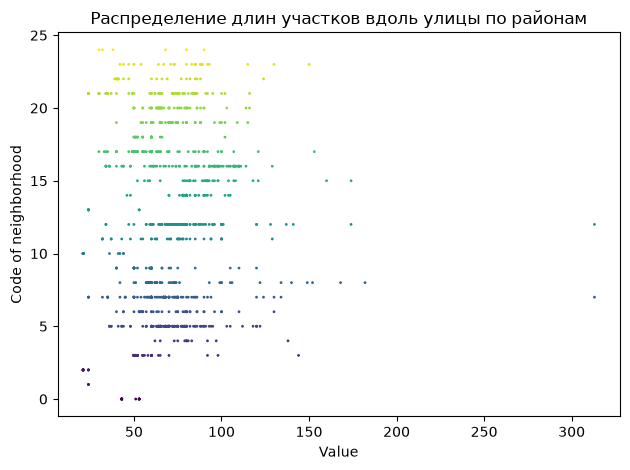

In [18]:
import matplotlib.pyplot as plt
print(f"Распределение по типу облицовки: {data.groupby('MasVnrType')['MasVnrType'].agg('count')}")
print(f"\nРаспределение по электрической системе: {data.groupby('Electrical')['Electrical'].agg('count')}")

temp_DF = pd.DataFrame()
temp_DF['Neighborhood'] = data['Neighborhood']
temp_DF['LotFrontage'] = data['LotFrontage']
temp_DF['Neighborhood'] = temp_DF['Neighborhood'].astype('category')
temp_DF['Neighborhood_Codes'] = temp_DF['Neighborhood'].cat.codes

fig, ax = plt.subplots()
ax.scatter(temp_DF['LotFrontage'], temp_DF['Neighborhood_Codes'], c=temp_DF['Neighborhood_Codes'], s=1)
ax.set_xlabel('Value')
ax.set_ylabel('Code of neighborhood')
ax.set_title('Распределение длин участков вдоль улицы по районам')
plt.tight_layout()
plt.show

med_by_hood = data.groupby('Neighborhood')['LotFrontage'].median()
print(f"\nОбщая медиана: {data['LotFrontage'].median():.1f}")
print(f"Std медиан по районам: {med_by_hood.std():.1f}")
print(f"Разброс медиан: {med_by_hood.max() - med_by_hood.min():.1f}")

In [19]:
case1 = data['MasVnrType'].isna() & (data['MasVnrArea'] > 0)
print(f"Площадь облицовки > 0, тип облицовки = NaN: {case1.sum()}")

case2 = (~data['MasVnrType'].isna()) & (data['MasVnrArea'] == 0)
print(f"Площадь облицовки = 0, тип облицовки != NaN: {case2.sum()}")

Площадь облицовки > 0, тип облицовки = NaN: 5
Площадь облицовки = 0, тип облицовки != NaN: 2


Фичи PoolQC, MiscFeature, Alley, Fence, FireplaceQu, Garage, Bsmt заполняем значениями None, для остальных необходимо заполнить по логике.
1) Если MasVnrType = NaN и MasVnrArea = 0, заменяем NaN на None;
если MasVnrType = NaN, но MasVnrArea > 0, заменяем NaN на моду, так как облицовка есть, такое условие встречается 5 раз из выборки, соответственно замена на моду не окажет сильного влияния на выборку; 
если MasVnrType != NaN , но MasVnrArea = 0, заменяем значение на None, так как облицовки нет(площадь=0) и её тип не несёт никакого смысла;
2) LotFrontage - заполняем медианой по району, по графику и численному анализу видно, что есть зависимость.
3) Electrical - пропуск всего один, можно заполнить модой, так как в фиче всего один пропуск.

In [34]:
num_cols = data.select_dtypes(exclude='object').columns.tolist()
corr_num = data[num_cols].corr()['SalePrice'].drop('SalePrice')
corr_num = corr_num.sort_values(ascending=False)

print("Топ-15 корреляций:")
print(corr_num.head(15).to_string())
print("\nТоп-15 корреляций с конца:")
print(corr_num.tail(15).to_string())

Топ-15 корреляций:
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
LotFrontage     0.351799

Топ-15 корреляций с конца:
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907


По таблицам корреляций видно, что большинство фичей имеют неплохую положительную корреляцию с таргетом. Из фичей, которые имеют слабую связь можно выделить:
1) YrSold, MoSold - слабые корреляции, так как основной диапазон продаж 2006-2010 года(не происходит резкого роста или упадка цен)
2) KitchenAbvGr - отрицательная корреляция, возможно связанно с тем, что большое количество кухонь определяют многоквартирные дома, из-за чего цена падает.
3) PoolArea - низкая корреляция объяснима тем, что большинство объектов выборки со значением 0.
4) BsmtFinSF2 - низкая корреляция объяснима тем, что большинство объектов выборки со значением 0.
5) BsmtHalfBath - низкая корреляция объяснима тем, что большинство объектов выборки со значением 0.
6) BsmtUnfSF - положительная корреляция неотделанного подвала с таргетом.
7) OverallCond - слабая корреляция с таргетом из-за преобладания класса 5, но достаточно важный признак для стоимости, необходимо проверить важность при обучении.
8) MSSubClass - корреляция слабая по причине того, что классы зданий расположены не линейно, здания дороже могут иметь значение класса ниже, чем дешёвые здания и наоборот

In [35]:
corr_matrix = data[num_cols].drop(columns=['SalePrice']).corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr = upper.stack().sort_values(ascending=False).head(15)

print("Топ-15 коррелирующих пар:")
print(high_corr.to_string())

Топ-15 коррелирующих пар:
GarageCars    GarageArea      0.882475
YearBuilt     GarageYrBlt     0.825667
GrLivArea     TotRmsAbvGrd    0.825489
TotalBsmtSF   1stFlrSF        0.819530
2ndFlrSF      GrLivArea       0.687501
BedroomAbvGr  TotRmsAbvGrd    0.676620
BsmtFinSF1    BsmtFullBath    0.649212
YearRemodAdd  GarageYrBlt     0.642277
GrLivArea     FullBath        0.630012
2ndFlrSF      TotRmsAbvGrd    0.616423
              HalfBath        0.609707
OverallQual   GarageCars      0.600671
              GrLivArea       0.593007
YearBuilt     YearRemodAdd    0.592855
GarageYrBlt   GarageCars      0.588920


Выводы по мультиколлинеарности:
1) GarageCars, GarageArea - больше гараж по площади, больше вместительность для машин (можно убрать вместительность гаража по машинам)
2) YearBuilt, GarageYrBlt - 1089 записей, где год постройки совпадает (возможно можно удалить GarageYrBlt)
3) GrLivArea, TotRmsAbvGrd - больше жилая площадь, больше комнат (оставляем оба признака, возможно можно удалить TotRmsAbvGrd)
4) TotalBsmtSF, 1stFlrSF - большее количество записей, где площадь подвала меньше либо равна площади первого этажа (оставляем оба признака)
5) 2ndFlrSF, GrLivArea - больше жилая площадь, больше площадь второго этажа (оставляем оба признака)
6) BsmtFinSF1, BsmtFullBath - больше отделанного подвала, больше санузлов там (оставляем оба признака)
7) YearRemodAdd, GarageYrBlt - (возможно можно удалить GarageYrBlt
8) GrLivArea, FullBath - больше жилая площадь, больше ванных комнат (оставляем оба признака, возможно можем удалить FullBath)
9) 2ndFlrSF, TotRmsAbvGrd - больше жилая площадь, больше комнат (оставляем оба признака, возможно можно удалить TotRmsAbvGrd)
10) 2ndFlrSF, HalfBath - больше жилая площадь, больше ванных комнат (оставляем оба признака, возможно можно удалить HalfBath)
11) OverallQual, GarageCars - общее качество зависит от количества мест для машин в гараже (оставляем оба признака)
12) OverallQual, GrLivArea - общее качество зависит от жилой площади (оставляем оба признака)
13) YearBuilt, YearRemodAdd - у половины зданий совпадает год ремонта и год постройки (оставляем оба признака, можно оставить один признак — год ремонта, но это приведёт к потере возраста дома: дом 1900 года постройки без ремонта и дом 2000 года постройки без ремонта будут неотличимы)
14) GarageYrBlt, GarageCars - новые дома с новым гаражом, больше машин (возможно можно удалить GarageYrBlt)

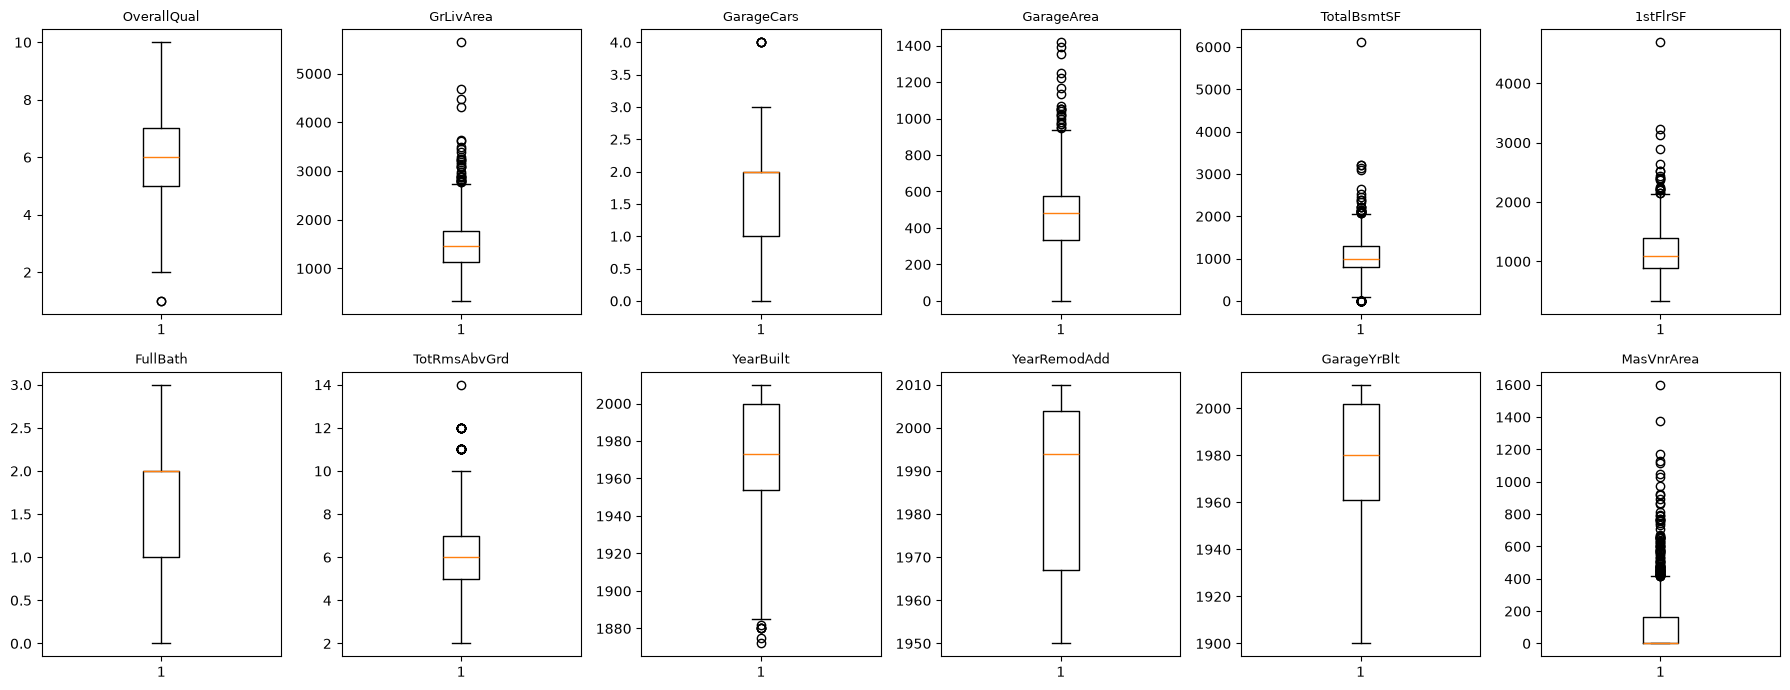

375    1
533    1
Name: OverallQual, dtype: int64


In [ ]:
top_num = corr_num.head(12).index.tolist()

fig, axes = plt.subplots(2, 6, figsize=(18, 7))
axes = axes.flatten()

for i, col in enumerate(top_num):
    axes[i].boxplot(data[col].dropna())
    axes[i].set_title(col, fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
print(f"Количество выбросов OverallQual: {len(data[data['OverallQual']<2]['OverallQual'])}")
print(f"Количество выбросов GrLivArea: {len(data[data['GrLivArea']>2600]['GrLivArea'])}")
print(f"Количество выбросов GarageCars: {len(data[data['GarageCars']>3.5]['GarageCars'])}")
print(f"Количество выбросов GarageArea: {len(data[data['GarageArea']>940]['GarageArea'])}")
print(f"Количество выбросов TotalBsmtSF: {len(data[(data['TotalBsmtSF']>2000) | (data['TotalBsmtSF']<100)]['TotalBsmtSF'])}")
print(f"Количество выбросов 1stFlrSF: {len(data[data['1stFlrSF']>2100]['1stFlrSF'])}")
print(f"Количество выбросов TotRmsAbvGrd: {len(data[data['TotRmsAbvGrd']>10]['TotRmsAbvGrd'])}")
print(f"Количество выбросов YearBuilt: {len(data[data['YearBuilt']<1885]['YearBuilt'])}")
print(f"Количество выбросов MasVnrArea: {len(data[data['MasVnrArea']>400]['MasVnrArea'])}")

Количество выбросов OverallQual: 2
Количество выбросов GrLivArea: 53
Количество выбросов GarageCars: 5
Количество выбросов GarageArea: 21
Количество выбросов TotalBsmtSF: 67
Количество выбросов 1stFlrSF: 26
Количество выбросов TotRmsAbvGrd: 30
Количество выбросов YearBuilt: 7
Количество выбросов MasVnrArea: 100


Анализ диаграммы размаха:
1) OverallQual: имеет достаточно хорошее распределение, медиана находится посередине 25 и 75 квартилей. Также имеет 2 выборса со значением 1.(оставить как есть)
2) GrLivArea - медина смещена к значению 75 кваритиля, за пределами 25 и 75 квартилей данные распределены нормально, есть 53 выыброса(проверить топ-10 выбросов)
3) GarageCars - медина смещена к значению 75 кваритиля, за пределами 25 и 75 квартилей данные распределены нормально, есть 4 выброса со значением 4(оставить, как есть)
4) GarageArea - медиана смещена вправо, за пределами 25 и 75 квартилей данные распределены нормально, выбросы есть, но не колосально отличаются от данных(21 выброс, оставляем как есть)
5) TotalBsmtSF - смещение по медиане влево, за пределами 25 и 75 квартилей данные распределены нормально, есть выбросы с двух сторон(проверить выбросы)
6) 1stFlrSF - смещение по медиане есть влево, правый ус длиннее левого(проверить большая площадь и низкая цена)
7) FullBath - медина смещена к значению 75 кваритиля, за пределами 25 и 75 квартилей данные распределены нормально, выбросов нет(оставить, как есть)
8) TotRmsAbvGrd - медиана расположена посередине, данные за пределами 25 и 75 квартилей распределены нормально, есть выбросы(проверить много комнат и низкая цена)
9) YearBuilt - медиана смещена левее, левый ус длиннее правого, выбросы есть ниже значения 1885, числа меньше 25 квантиля имеют разброс сильнее, чем числа больше 75 квартиля(оставить как есть)
10) YearRemodAdd - медиана смещена вправо, левый ус длиннее правого, выбросов нет, числа меньше 25 квантиля имеют разброс сильнее, чем числа больше 75 квартиля(оставить как есть)
11) GarageYrBlt - медиана расположена посередине, выбросов нет, левый ус длиннее правого, числа меньше 25 квантиля имеют разброс сильнее, чем числа больше 75 квартиля(оставить как есть)
12) MasVnrArea - медиана смещена к нулю, длина левого уса относительно правого практически нулевая, имеет много выбросов(проверить log1p)

In [ ]:
for col in ['GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'TotRmsAbvGrd']:
    print('\nТоп-10 выбросов ', col)
    print(data.nlargest(10, col)[[col, 'SalePrice', 'OverallQual']])


Топ-10 выбросов  GrLivArea
      GrLivArea  SalePrice  OverallQual
1298       5642     160000           10
523        4676     184750           10
1182       4476     745000           10
691        4316     755000           10
1169       3627     625000           10
185        3608     475000           10
304        3493     295000            7
1268       3447     381000            8
635        3395     200000            6
769        3279     538000            8

Топ-10 выбросов  TotalBsmtSF
      TotalBsmtSF  SalePrice  OverallQual
1298         6110     160000           10
332          3206     284000            8
496          3200     430000            8
523          3138     184750           10
440          3094     555000           10
1373         2633     466500           10
1044         2524     278000            8
691          2444     755000           10
1182         2396     745000           10
224          2392     386250           10

Топ-10 выбросов  1stFlrSF
      1stFlrS

По данным выбросов id 1298, 523 удаляются, слишком малая цена для показанных площадей и количества комнат. Явные аномалии.

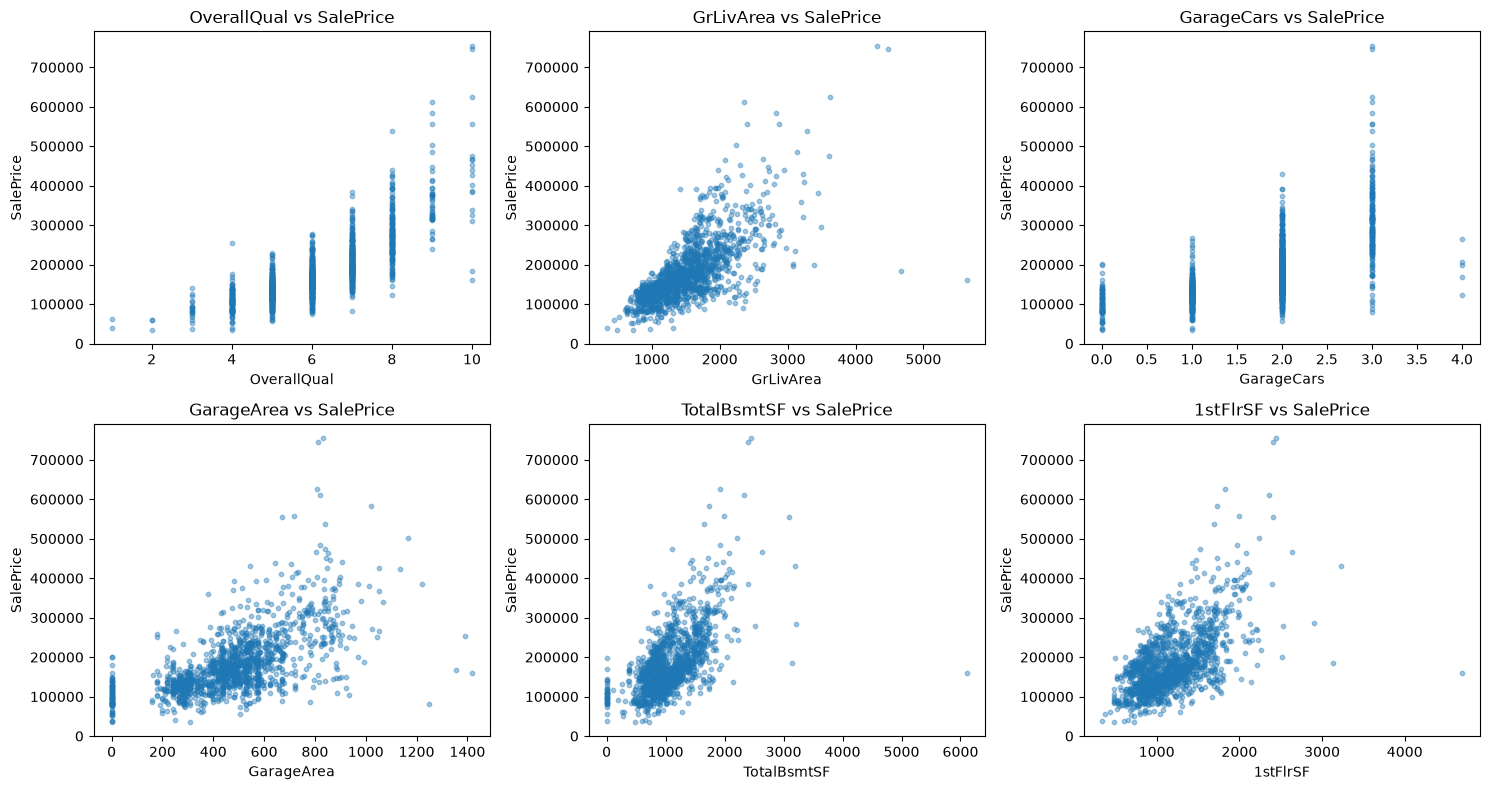

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
top6 = corr_num.head(6).index.tolist()

for i, col in enumerate(top6):
    axes[i].scatter(data[col], data['SalePrice'], alpha=0.4, s=10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('SalePrice')
    axes[i].set_title(f'{col} vs SalePrice')

plt.tight_layout()
plt.show()

1) OverallQual, GarageCars - дискретные, монотонная связь, точки выстраиваются в столбцы.
2) GrLivArea - чёткая линейная связь, но выражена гетероскедастичность (разброс растёт с площадью).
3) GarageArea, TotalBsmtSF - линия на 0 (дома без гаража/подвала) + гетероскедастичность после 200.
4) 1stFlrSF - связь шумнее, чем у GrLivArea (площадь первого этажа — часть общей).
Кандидаты на feature engineering:
1) HasGarage = есть гараж/нет гаража.
2) HasBasement = есть подвал/нет подвала.

In [30]:
cat_cols_all = data.select_dtypes(include='object').columns.tolist()

for col in cat_cols_all:
    grp = data.groupby(col)['SalePrice'].agg(['median', 'count'])
    grp = grp.sort_values('median', ascending=False)
    ratio = grp['median'].max() / grp['median'].min()

    if ratio > 1.5 or len(grp) <= 5:
        print(f"{col} (ratio={ratio:.2f}, категорий={len(grp)})")
        print(grp.head(10).to_string())

MSZoning (ratio=2.76, категорий=5)
            median  count
MSZoning                 
FV        205950.0     65
RL        174000.0   1151
RH        136500.0     16
RM        120500.0    218
C (all)    74700.0     10
Street (ratio=1.43, категорий=2)
          median  count
Street                 
Pave    163000.0   1454
Grvl    114250.0      6
Alley (ratio=1.44, категорий=2)
         median  count
Alley                 
Pave   172500.0     41
Grvl   119500.0     50
LotShape (ratio=1.51, категорий=4)
            median  count
LotShape                 
IR2       221000.0     41
IR3       203570.0     10
IR1       189000.0    484
Reg       146000.0    925
LandContour (ratio=1.59, категорий=4)
               median  count
LandContour                 
HLS          222250.0     50
Low          190000.0     36
Lvl          162900.0   1311
Bnk          139400.0     63
Utilities (ratio=1.19, категорий=2)
             median  count
Utilities                 
AllPub     163000.0   1459
NoSeWa    

/tmp/ipykernel_6320/4100536432.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_all = data.select_dtypes(include='object').columns.tolist()


Вывод по анализу медиан:
Сильные фичи (ratio > 2.5, достаточно данных):
1) ExterQual (4.43)
2) Exterior1st (3.69)
3) Neighborhood (3.58)
4) Exterior2nd (3.04)
5) BsmtCond (3.03)
6) BsmtQual (2.84)
7) MSZoning (2.76)
8) KitchenQual (2.75).

Сильные фичи, но с проблемами данных:
1) Condition2 (3.36) - по 1-2 наблюдения в категориях.
2) PoolQC (2.87) - 7 наблюдений.
3) MiscFeature (2.66) - есть редкие категории.
4) Electrical (2.54) - присутствует дисбаланс типов.

Умеренные фичи (2 < ratio < 2.5):
RoofMatl, FireplaceQu, SaleCondition, SaleType, Heating, HeatingQC, ExterCond, GarageQual, GarageType.

Ординальные шкалы:
ExterQual, BsmtQual, KitchenQual, FireplaceQu, HeatingQC, BsmtCond, GarageFinish - монотонно упорядочены, будет применён ordinal encoding.

Спорные (порядок нечёткий): 
BsmtExposure, BsmtFinType1, Functional — проверить экспериментом ordinal и category.

Аномальный порядок: 
ExterCond, GarageQual, GarageCond - нарушение монотонности из-за малых выборок в Ex.

# Общие выводы по EDA

**Пропуски**

Замена NaN на None:
- PoolQC;
- MiscFeature;
- Alley;
- Fence;
- FireplaceQu;
- Garage;
- Bsmt;
- MasVnrType при условии MasVnrType = NaN и MasVnrArea = 0;
- MasVnrType при условии MasVnrType != NaN и MasVnrArea = 0.

Замена на значения:
- MasVnrType на моду при условии MasVnrType = NaN, но MasVnrArea > 0;
- LotFrontage на медиану по Neighborhood;
- Electrical на моду.

Эксперимент:
- замена NaN в GarageYrBlt на YearBuilt;

Удаление:
- Utilities;
- Street;
- Condition2;
- MiscFeature;
- PoolQC;
- PoolArea;
- Heating.

**Мультиколлинеарность**

Необходима проверка:
- GarageCars, нужно посмотреть по важности фич при обучении.

Эксперимент:
- удаление GarageYrBlt;
- удаление TotRmsAbvGrd;
- удаление FullBath;
- удаление HalfBath.

**Выбросы и нормализация**

Удаление выбросов:
- id 1298
- id 523

Эксперимент при обучении:
- MasVnrArea

**Анализ медиан**

Ordinal encoding:
- ExterQual
- BsmtQual
- KitchenQual
- FireplaceQu
- HeatingQC
- BsmtCond
- GarageFinish

Эксперимент ordinal encoding и category
- BsmtExposure
- BsmtFinType1
- Functional

# Эксперементы с данными

In [ ]:
model_full = lgb.LGBMRegressor(
    objective='regression',
    metric='rmse',
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    min_child_samples=20,
    random_state=42,
    force_col_wise=True,
    verbose=-1
)
model_full.fit(X_train, y_train, categorical_feature=cat_cols)

importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'gain': model_full.booster_.feature_importance(importance_type='gain'),
    'split': model_full.booster_.feature_importance(importance_type='split'),
}).sort_values('gain', ascending=False)

print(importance_df.head(30))

         feature          gain  split
16   OverallQual  3.420390e+13    249
45     GrLivArea  8.189936e+12   1051
11  Neighborhood  6.362713e+12    390
37   TotalBsmtSF  3.510539e+12    694
33    BsmtFinSF1  2.204374e+12    695
42      1stFlrSF  1.673689e+12    661
60    GarageCars  1.474301e+12     62
26     ExterQual  1.472358e+12     95
3        LotArea  1.312578e+12    708
53  TotRmsAbvGrd  1.113444e+12    134
61    GarageArea  7.055066e+11    656
48      FullBath  5.221476e+11     43
43      2ndFlrSF  4.787106e+11    399
18     YearBuilt  4.124101e+11    314
65    WoodDeckSF  3.794182e+11    351
19  YearRemodAdd  3.782186e+11    254
17   OverallCond  3.640413e+11    160
25    MasVnrArea  3.578753e+11    571
2    LotFrontage  3.544807e+11    656
58   GarageYrBlt  3.306744e+11    400
66   OpenPorchSF  3.044869e+11    645
36     BsmtUnfSF  2.186487e+11    461
55    Fireplaces  1.608339e+11     56
59  GarageFinish  1.090817e+11    104
75        MoSold  1.080374e+11    310
76        Yr

In [ ]:
print(importance_df.tail(30))

         feature          gain  split
51  KitchenAbvGr  4.806317e+09      3
52   KitchenQual  4.331222e+09     29
23   Exterior2nd  3.738960e+09     38
47  BsmtHalfBath  2.809239e+09     30
39     HeatingQC  2.730973e+09      8
15    HouseStyle  1.940038e+09     11
5          Alley  1.938507e+09      5
7    LandContour  1.633097e+09     14
41    Electrical  1.523258e+09     25
73   MiscFeature  7.526883e+08      9
28    Foundation  7.396818e+08     18
20     RoofStyle  5.378102e+08      9
27     ExterCond  3.804418e+08     14
77      SaleType  2.276643e+08      7
74       MiscVal  1.135174e+08      2
72         Fence  9.825110e+07      4
1       MSZoning  3.146280e+07      1
4         Street  0.000000e+00      0
14      BldgType  0.000000e+00      0
13    Condition2  0.000000e+00      0
8      Utilities  0.000000e+00      0
21      RoofMatl  0.000000e+00      0
34  BsmtFinType2  0.000000e+00      0
38       Heating  0.000000e+00      0
62    GarageQual  0.000000e+00      0
54    Functi

In [29]:
for col in ['GarageCond', '3SsnPorch', 'Functional', 'GarageQual', 'BsmtFinType2', 'RoofMatl', 'BldgType']:
    print(data.groupby(col)[col].agg('count'))

GarageCond
Ex       2
Fa      35
Gd       9
Po       7
TA    1326
Name: GarageCond, dtype: int64
3SsnPorch
0      1436
23        1
96        1
130       1
140       1
144       2
153       1
162       1
168       3
180       2
182       1
196       1
216       2
238       1
245       1
290       1
304       1
320       1
407       1
508       1
Name: 3SsnPorch, dtype: int64
Functional
Maj1      14
Maj2       5
Min1      31
Min2      34
Mod       15
Sev        1
Typ     1360
Name: Functional, dtype: int64
GarageQual
Ex       3
Fa      48
Gd      14
Po       3
TA    1311
Name: GarageQual, dtype: int64
BsmtFinType2
ALQ      19
BLQ      33
GLQ      14
LwQ      46
Rec      54
Unf    1256
Name: BsmtFinType2, dtype: int64
RoofMatl
ClyTile       1
CompShg    1434
Membran       1
Metal         1
Roll          1
Tar&Grv      11
WdShake       5
WdShngl       6
Name: RoofMatl, dtype: int64
BldgType
1Fam      1220
2fmCon      31
Duplex      52
Twnhs       43
TwnhsE     114
Name: BldgType, dtype: in

Исходя из топ-30 по важности:
1) GarageCars занимает 7-е место, следует убрать пункт с проверкой на удаление GarageCars.
2) TotRmsAbvGrd убрать эксперимент с удалением, фича важна.
3) FullBath убрать эксперимент с удалением, фича важна.
4) GarageYrBlt является важной фичей, проверить эксперименты.

Исходя из топ-30 по неважности:
1) Street, Utilities, Condition2, Heating, PoolArea, PoolQC - подтверждается удаление.
2) GarageCond, Functional, GarageQual, BsmtFinType2, RoofMatl, BldgType - имеют дисбаланс классов.
3) 3SsnPorch - преобладает 0 в 1436 объектах, почти константа.
4) Exterior2nd - дублирует Exterior1st
5) Electrical - дисбаланс, но сильная по EDA

**Удалить:**
- 3SsnPorch;
- Electrical;
- Exterior2nd;
- GarageCond;
- Functional;
- GarageQual;
- BsmtFinType2;
- RoofMatl;
- BldgType;
- Street;
- Utilities;
- Condition2;
- Heating;
- PoolArea;
- PoolQC.

**Эксперименты**

Низкая важность, но сильная фича в EDA:
- KitchenQual;
- MSZoning.

Низкая важность, но не плохая фича в EDA:
- Fence;
- SaleType;
- ExterCond;
- RoofStyle;
- Foundation;
- LandContour;
- Alley;
- HouseStyle;
- HeatingQC;
- BsmtHalfBath;
- KitchenAbvGr.

# Эксперемент №1 Удаление фич, которые не использовал бейзлайне.

In [50]:
cols_gain_zero = ['Street', 'Utilities', 'Condition2', 'Heating', 'PoolArea', 'PoolQC']

X_train_exp = X_train.drop(columns=cols_gain_zero)
cat_cols_exp = [c for c in cat_cols if c not in cols_gain_zero]

scores = []
for train_idx, val_idx in kfold.split(X_train_exp, y_train):
    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr, 
        categorical_feature=cat_cols_exp,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)])

    pred = model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))

scores = np.array(scores)

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [51]:
print(f"RMSE: {scores.mean():.2f}")
print(f"RMSE std: {scores.std():.2f}")
print(f"Разница с бейзлайном: {rmse_baseline_lgb - scores.mean():.2f}")
print(f"По фолдам: {np.round(rmse_folds_baseline_lgb, 2) - np.round(scores, 2)}")

RMSE: 28504.28
RMSE std: 5411.32
Разница с бейзлайном: 0.00
По фолдам: [0. 0. 0. 0. 0.]


**Вывод по эксперименту №1**
Разница в RMSE показывает, что выбранные для удаления фичи не использовались в бейзлайне(gain=0) и демонстрируют то, что их удаление для обучения никак не влияет на результат, следовательно удаление безопасно.

# Эксперемент №2 Удаление фич с высоким дисбалансом.

In [53]:
cols_gain_zero = ['Street', 'Utilities', 'Condition2', 'Heating', 'PoolArea', 'PoolQC']
cols_with_imbalance = ['GarageCond', 'Functional', 'GarageQual', 'BsmtFinType2', 'RoofMatl', 'BldgType']
cols_for_delete = cols_gain_zero + cols_with_imbalance

X_train_exp = X_train.drop(columns=cols_for_delete)
cat_cols_exp = [c for c in cat_cols if c not in cols_for_delete]

scores = []
for train_idx, val_idx in kfold.split(X_train_exp, y_train):
    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols_exp,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
        )

    pred=model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))
scores = np.array(scores)

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [54]:
print(f"RMSE: {scores.mean():.2f}")
print(f"RMSE std: {scores.std():.2f}")
print(f"Разница с бейзлайном: {(rmse_baseline_lgb - scores.mean()):.2f}")
print(f"По фолдам: {np.round(rmse_folds_baseline_lgb, 2) - np.round(scores, 2)}")

RMSE: 28461.66
RMSE std: 5427.61
Разница с бейзлайном: 42.62
По фолдам: [  0.     0.     0.   213.09   0.  ]


**Вывод по эксперименту №2**
Разница в RMSE показывает, что выбранные для удаления фичи(gain=0 и дисбаланс) даёт небольшое улучшение(0.8% от std). Можно сделать вывод, что удаление фичей с дисбалансом безопасно. Также можно заметить, что изменения коснулись только 4-ого фолда, с большей вероятностью бейзлайн не использовал удалённые фичи в оставшихся фолдах.

# Эксперемент №3 Удаление фич со смешенными замечаниями.

In [99]:
cols_gain_zero = ['Street', 'Utilities', 'Condition2', 'Heating', 'PoolArea', 'PoolQC']
cols_with_imbalance = ['GarageCond', 'Functional', 'GarageQual', 'BsmtFinType2', 'RoofMatl', 'BldgType']
cols_with_mixed_problems = ['Electrical', '3SsnPorch', 'Exterior2nd']

cols_for_delete = cols_gain_zero + cols_with_imbalance + cols_with_mixed_problems

X_train_exp = X_train.drop(columns=cols_for_delete)
cat_cols_exp = [c for c in cat_cols if c not in cols_for_delete]

scores = []
for train_idx, train_val in kfold.split(X_train_exp, y_train):

    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[train_val]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[train_val]

    model=lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols_exp,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    pred = model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))
scores = np.array(scores)

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [100]:
print(f"RMSE: {scores.mean():.2f}")
print(f"RMSE std: {scores.std():.2f}")
print(f"Разница с бейзлайном {(rmse_baseline_lgb - scores.mean()):.2f}")
print(f"По фолдам {np.round(rmse_folds_baseline_lgb, 2) - np.round(scores, 2)}")

RMSE: 28457.53
RMSE std: 5479.26
Разница с бейзлайном 46.75
По фолдам [   6.86 -165.38  199.78  192.47    0.  ]


**Вывод по эксперименту №3**
Улучшение RMSE находится в пределах шума(0.8% от std 5411), но с этим появляется неустойчивость модели: ухудшение по сравнению с бейзлайном в 3-ёх из 5-ти фолдов.
Есть возможность влияние фичей по отдельности или сделать попарное использование фичей друг с другом. Эти решения могли бы использоваться, если влияение выбранных фичей было выше. В данном случае было принято решение не удалять фичи(3SsnPorch, Electrical, Exterior2nd) при обучении.

# Эксперемент №4 Удаление выбросов.

In [96]:
print(X_train.loc[[1298, 523], ['GrLivArea', 'OverallQual']])
print(y_train.loc[[1298, 523]])

      GrLivArea  OverallQual
1298       5642           10
523        4676           10
1298    160000
523     184750
Name: SalePrice, dtype: int64


In [110]:
outliers_idx = [1298, 523]

X_train_exp = X_train.drop(index=outliers_idx)
y_train_exp = y_train.drop(index=outliers_idx)

scores = []
for train_idx, train_val in kfold.split(X_train_exp, y_train_exp):

    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[train_val]
    y_tr, y_val = y_train_exp.iloc[train_idx], y_train_exp.iloc[train_val]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    pred = model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))
scores = np.array(scores)

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [111]:
print(f"RMSE: {scores.mean():.2f}")
print(f"RMSE std: {scores.std():.2f}")
print(f"Разница с бейзлайном {(rmse_baseline_lgb - scores.mean()):.2f}")
print(f"По фолдам {np.round(rmse_folds_baseline_lgb, 2) - np.round(scores, 2)}")

RMSE: 24606.06
RMSE std: 2623.25
Разница с бейзлайном 3898.21
По фолдам [ 1550.95 13797.7   2226.29  -637.    2553.11]


**Вывод по эксперименту №4**
Удаление двух выбросов оказало сильное влияние на RMSE(разница с бейзлайном 3898.21 - значительное улучшение), стандартное отклонение уменьшилось в 2 раза(разброс между фолдами уменьшился). Обе аномалии попали в фолд 2, который в бейзлайне давал 38062. Это объясняет основную часть улучшения. Необходимо удалить объекты с id 1298 и 523.

In [ ]:
rmse_without_outliers = scores.mean()
rmse_folds_without_outliers = scores

# Эксперемент №5 Проверка GarageYrBlt.

In [113]:
outliers_idx = [1298, 523]

X_train_exp = X_train.copy()
X_train_exp['GarageYrBlt'] = X_train_exp['GarageYrBlt'].fillna(X_train_exp['YearBuilt'])
X_train_exp = X_train_exp.drop(index=outliers_idx)
y_train_exp = y_train.drop(index=outliers_idx)

scores = []
for train_idx, train_val in kfold.split(X_train_exp, y_train_exp):

    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[train_val]
    y_tr, y_val = y_train_exp.iloc[train_idx], y_train_exp.iloc[train_val]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    pred = model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))
scores = np.array(scores)

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [115]:
print(f"RMSE: {scores.mean():.2f}")
print(f"RMSE std: {scores.std():.2f}")
print(f"Разница с моделью без выбросов {(rmse_without_outliers - scores.mean()):.2f}")
print(f"По фолдам без выбросов {np.round(rmse_folds_without_outliers, 2) - np.round(scores, 2)}")

RMSE: 24810.37
RMSE std: 2606.04
Разница с моделью без выбросов -204.30
По фолдам без выбросов [  36.51 -255.77   -8.03  118.96 -913.19]


**Вывод по эксперименту №5**
Замена значений NaN на YearBuilt дало увеличение RMSE, по фолдам увеличение RMSE в 3 из 5 случаев. Логичное изменение, NaN показывает зачастую на отсутствие гаража, следовательно NaN будет давать больше информативности, чем YearBuilt. Не производим замену.

# Эксперемент №6 Добавление фичей.

In [116]:
outliers_idx = [1298, 523]

X_train_exp = X_train.copy()
X_train_exp['Age'] = X_train_exp['YrSold'] - X_train_exp['YearBuilt']
X_train_exp['RemodAge'] = X_train_exp['YrSold'] - X_train_exp['YearRemodAdd']
X_train_exp['WasRemodeled'] = (X_train_exp['YearRemodAdd'] != X_train_exp['YearBuilt']).astype(int)
X_train_exp['HasGarage'] = (X_train_exp['GarageArea'] > 0).astype(int)
X_train_exp['HasBasement'] = (X_train_exp['TotalBsmtSF'] > 0).astype(int)

X_train_exp = X_train_exp.drop(index=outliers_idx)
y_train_exp = y_train.drop(index=outliers_idx)

cat_cols_exp = cat_cols.copy()

scores = []
for train_idx, train_val in kfold.split(X_train_exp, y_train_exp):

    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[train_val]
    y_tr, y_val = y_train_exp.iloc[train_idx], y_train_exp.iloc[train_val]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols_exp,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    pred = model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))
scores = np.array(scores)

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [117]:
print(f"RMSE: {scores.mean():.2f}")
print(f"RMSE std: {scores.std():.2f}")
print(f"Разница с моделью без выбросов {(rmse_without_outliers - scores.mean()):.2f}")
print(f"По фолдам без выбросов {np.round(rmse_folds_without_outliers, 2) - np.round(scores, 2)}")

RMSE: 24875.36
RMSE std: 2605.36
Разница с моделью без выбросов -269.30
По фолдам без выбросов [ -73.42 -259.54 -216.59  133.55 -930.5 ]


**Вывод по эксперименту №6**
Добавление 5-ти фич(Age, RemodAge, WasRemodeled, HasGarage, HasBasement) увеличило RMSE. По фолдам ухудшил в 4-ёх из 5-ти. Это могло произойти по причине Age и RemodAge являются линейными комбинацями YrSold, YearBuilt, YearRemodAdd, которые LightGBM может выучить самостоятельно. WasRemodeled, HasGarage, HasBasement дублируют информацию из исходных фич. Использовать исходный набор фич.

# Эксперемент №7 Проверка LotFrontage.

In [128]:
outliers_idx = [1298, 523]

X_train_exp = X_train.copy()
X_train_exp['LotFrontage'] = X_train_exp.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)
X_train_exp = X_train_exp.drop(index=outliers_idx)
y_train_exp = y_train.drop(index=outliers_idx)

cat_cols_exp = cat_cols.copy()

scores = []
for train_idx, train_val in kfold.split(X_train_exp, y_train_exp):

    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[train_val]
    y_tr, y_val = y_train_exp.iloc[train_idx], y_train_exp.iloc[train_val]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols_exp,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    pred = model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))
scores = np.array(scores)

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [129]:
print(f"RMSE: {scores.mean():.2f}")
print(f"RMSE std: {scores.std():.2f}")
print(f"Разница с моделью без выбросов {(rmse_without_outliers - scores.mean()):.2f}")
print(f"По фолдам без выбросов {np.round(rmse_folds_without_outliers, 2) - np.round(scores, 2)}")

RMSE: 24931.04
RMSE std: 2535.70
Разница с моделью без выбросов -324.97
По фолдам без выбросов [ -157.03  -449.95   -46.83   176.51 -1147.57]


**Вывод по эксперименту №7**
Заполнение LotFrontage медианой по Neighborhood увеличило RMSE, по фолдам: ухудшение в 4-ёх из 5-ти.
Возможно NaN в LotFrontage информативен. Также в некоторых районах медиана вычисляется по малым выборкам, что ненадёжно. Не выполняем замену.

# Эксперемент №8 Проверка ordinal encoding.

In [ ]:
outliers_idx = [1298, 523]

X_train_exp = X_train.copy()

exposure_map = {'No': 0, 'Mn': 1, 'Av': 2, 'Gd': 3}
X_train_exp['BsmtExposure'] = X_train_exp['BsmtExposure'].astype(str).map(exposure_map).fillna(-1).astype(int)

fin_map = {'Unf': 0, 'LwQ': 1, 'Rec': 2, 'BLQ': 3, 'ALQ': 4, 'GLQ': 5}
X_train_exp['BsmtFinType1'] = X_train_exp['BsmtFinType1'].astype(str).map(fin_map).fillna(-1).astype(int)

X_train_exp = X_train_exp.drop(index=outliers_idx)
y_train_exp = y_train.drop(index=outliers_idx)

cat_cols_exp = [c for c in cat_cols if c not in ['BsmtExposure', 'BsmtFinType1']]

scores = []
for train_idx, train_val in kfold.split(X_train_exp, y_train_exp):

    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[train_val]
    y_tr, y_val = y_train_exp.iloc[train_idx], y_train_exp.iloc[train_val]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols_exp,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )
    pred = model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))
scores = np.array(scores)

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [176]:
print(f"RMSE: {scores.mean():.2f}")
print(f"RMSE std: {scores.std():.2f}")
print(f"Разница с моделью без выбросов {(rmse_without_outliers - scores.mean()):.2f}")
print(f"По фолдам без выбросов {np.round(rmse_folds_without_outliers, 2) - np.round(scores, 2)}")

RMSE: 24744.38
RMSE std: 2479.38
Разница с моделью без выбросов -138.31
По фолдам без выбросов [-223.71  -21.64 -179.79  581.32 -847.75]


**Вывод по эксперименту №8**
Ordinal encoding для BsmtExposure и BsmtFinType1 увеличил RMSE. По фолдам: ухудшение в 4-ёх из 5-ти. BsmtFinType1 не является монотонным, и ordinal encoding навязывает ложный порядок. Не использовать ordinal для этих фич, оставить как category.

# Эксперемент №9 Проверка KitchenQual и MSZoning.

In [143]:
outliers_idx = [1298, 523]

X_train_exp = X_train.copy()
X_train_exp = X_train_exp.drop(columns=['KitchenQual', 'MSZoning'])
X_train_exp = X_train_exp.drop(index=outliers_idx)
y_train_exp = y_train.drop(index=outliers_idx)

cat_cols_exp = [c for c in cat_cols if c not in ['KitchenQual', 'MSZoning']]

scores = []
for train_idx, train_val in kfold.split(X_train_exp, y_train_exp):

    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[train_val]
    y_tr, y_val = y_train_exp.iloc[train_idx], y_train_exp.iloc[train_val]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols_exp,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    pred = model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))
scores = np.array(scores)

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [144]:
print(f"RMSE: {scores.mean():.2f}")
print(f"RMSE std: {scores.std():.2f}")
print(f"Разница с моделью без выбросов {(rmse_without_outliers - scores.mean()):.2f}")
print(f"По фолдам без выбросов {np.round(rmse_folds_without_outliers, 2) - np.round(scores, 2)}")

RMSE: 24737.98
RMSE std: 2725.20
Разница с моделью без выбросов -131.92
По фолдам без выбросов [ 159.8     0.   -263.1     0.   -556.28]


**Вывод по эксперименту №9**
Удаление KitchenQual и MSZoning увеличило RMSE и std. По фолдам: улучшение в 1-ом из 5-ти. Несмотря на низкую важность по gain, фичи используются моделью в отдельных фолдах. MSZoning дублирует Neighborhood, KitchenQual дублирует OverallQual, но не полностью. Необходимо оставить KitchenQual и MSZoning.

# Эксперемент №10 Проверка log1p для MasVnrArea.

In [146]:
outliers_idx = [1298, 523]

X_train_exp = X_train.copy()
X_train_exp['MasVnrArea'] = np.log1p(X_train_exp['MasVnrArea'])
X_train_exp = X_train_exp.drop(index=outliers_idx)
y_train_exp = y_train.drop(index=outliers_idx)

cat_cols_exp = cat_cols.copy()

scores = []
for train_idx, train_val in kfold.split(X_train_exp, y_train_exp):

    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[train_val]
    y_tr, y_val = y_train_exp.iloc[train_idx], y_train_exp.iloc[train_val]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols_exp,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    pred = model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))
scores = np.array(scores)

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [147]:
print(f"RMSE: {scores.mean():.2f}")
print(f"RMSE std: {scores.std():.2f}")
print(f"Разница с моделью без выбросов {(rmse_without_outliers - scores.mean()):.2f}")
print(f"По фолдам без выбросов {np.round(rmse_folds_without_outliers, 2) - np.round(scores, 2)}")

RMSE: 24608.52
RMSE std: 2625.71
Разница с моделью без выбросов -2.46
По фолдам без выбросов [  0.     0.   -11.41  -0.58  -0.3 ]


**Вывод по эксперименту №10**
log1p(MasVnrArea) не дал эффекта, RMSE практически не изменился. По фолдам 2 из 5-ти без изменений, остальные показали слабую разницу. MasVnrArea имеет низкую важность. Логарифмирование фичи, которая не входит в топ важных, не влияет на результат. Не применять log1p.

# Эксперемент №11 Объединение улучшений.

In [155]:
outliers_idx = [1298, 523]

cols_gain_zero = ['Street', 'Utilities', 'Condition2', 'Heating', 'PoolArea', 'PoolQC']
cols_with_imbalance = ['GarageCond', 'Functional', 'GarageQual', 'BsmtFinType2', 'RoofMatl', 'BldgType']
cols_for_delete = cols_gain_zero + cols_with_imbalance

X_train_exp = X_train.drop(columns=cols_for_delete)
X_train_exp = X_train_exp.drop(index=outliers_idx)
y_train_exp = y_train.drop(index=outliers_idx)

cat_cols_exp = [c for c in cat_cols if c not in cols_for_delete]

scores = []
for train_idx, train_val in kfold.split(X_train_exp, y_train_exp):

    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[train_val]
    y_tr, y_val = y_train_exp.iloc[train_idx], y_train_exp.iloc[train_val]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols_exp,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    pred = model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))
scores = np.array(scores)

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

In [156]:
print(f"RMSE: {scores.mean():.2f}")
print(f"RMSE std: {scores.std():.2f}")
print(f"Разница с моделью без выбросов {(rmse_without_outliers - scores.mean()):.2f}")
print(f"По фолдам без выбросов {np.round(rmse_folds_without_outliers, 2) - np.round(scores, 2)}")

RMSE: 24604.60
RMSE std: 2595.38
Разница с моделью без выбросов 1.46
По фолдам без выбросов [-49.3   0.    0.   56.6   0. ]


**Вывод по эксперименту №11**
Финальная конфигурация: удаление выбросов и удаление 12 фич. По RMSE улучшение 1.46 (0.06% от std, в пределах шума). std снизился с 2623 до 2595. Удаление 12 фич не даёт значимого улучшения, но делает модель чуть стабильнее и чище. Итоговый RMSE = 24604.60.

# Проверка RMSE на test.

In [ ]:
outliers_idx = [1298, 523]

cols_gain_zero = ['Street', 'Utilities', 'Condition2', 'Heating', 'PoolArea', 'PoolQC']
cols_with_imbalance = ['GarageCond', 'Functional', 'GarageQual', 'BsmtFinType2', 'RoofMatl', 'BldgType']
cols_for_delete = cols_gain_zero + cols_with_imbalance

X_train_exp = X_train.drop(columns=cols_for_delete)
X_train_exp = X_train_exp.drop(index=outliers_idx)
y_train_exp = y_train.drop(index=outliers_idx)

X_test_exp = X_test.drop(columns=cols_for_delete)

cat_cols_exp = [c for c in cat_cols if c not in cols_for_delete]

best_iters = []
scores = []
for train_idx, train_val in kfold.split(X_train_exp, y_train_exp):

    X_tr, X_val = X_train_exp.iloc[train_idx], X_train_exp.iloc[train_val]
    y_tr, y_val = y_train_exp.iloc[train_idx], y_train_exp.iloc[train_val]

    model = lgb.LGBMRegressor(
        objective='regression',
        metric='rmse',
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        random_state=42,
        force_col_wise=True
    )
    model.fit(
        X_tr, y_tr,
        categorical_feature=cat_cols_exp,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )
    best_iters.append(model.best_iteration_)

    pred = model.predict(X_val)
    scores.append(np.sqrt(np.mean((y_val - pred) ** 2)))

scores = np.array(scores)
n_optimal = int(np.mean(best_iters))

print(f"Best iterations по фолдам: {best_iters}")
print(f"Оптимальное n_estimators: {n_optimal}")
print(f"CV RMSE: {scores.mean():.2f} ± {scores.std():.2f}")

model_final = lgb.LGBMRegressor(
    objective='regression',
    metric='rmse',
    n_estimators=n_optimal,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    min_child_samples=20,
    random_state=42,
    force_col_wise=True
)
model_final.fit(X_train_exp, y_train_exp, categorical_feature=cat_cols_exp)

y_train_pred = model_final.predict(X_train_exp)
y_test_pred = model_final.predict(X_test_exp)

train_rmse = np.sqrt(np.mean((y_train_exp - y_train_pred) ** 2))
test_rmse = np.sqrt(np.mean((y_test - y_test_pred) ** 2))

/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/home/nikita/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=

Best iterations по фолдам: [136, 76, 1000, 232, 982]
Оптимальное n_estimators: 485
CV RMSE: 24604.60 ± 2595.38


In [165]:
print(f"\nTrain RMSE: {train_rmse:.2f}")
print(f"Test RMSE:  {test_rmse:.2f}")
print(f"CV RMSE:    {scores.mean():.2f}")
print(f"Разница train-test: {train_rmse - test_rmse:.2f}")


Train RMSE: 7601.39
Test RMSE:  25866.37
CV RMSE:    24604.60
Разница train-test: -18264.98


**Вывод по общим показателям**
Точность:
- Test RMSE = 25866.37, CV RMSE = 24604.60. Разница — 5%, в пределах нормы для малой тестовой выборки в 438 строк.
- Train RMSE = 7601 - переобучение есть, но не критичное.

Стабильность:
- CV std = 2595.38 при mean = 24604.60(10.5%). Модель стабильна по фолдам.
- Разброс по фолдам сократился с 5411 у бейзлайна до 2595 у итоговой модели после удаления выбросов.

Спецификация:
- Средний остаток -166 - модель не систематически смещена.
- std остатков = 25895 совпадает с Test RMSE.
- Переобучение снижено за счёт использования best_iteration_ из CV.

Итог: Основной прирост дало удаление выбросов (эксперимент 4). Удаление 12 фич (эксперимент 11) не дало значимого улучшения, но сделало модель чуть стабильнее. Модель адекватна - точность приемлема, стабильность высокая, спецификация корректна.